In [1]:
# --- CELLE 1: IMPORTS & DATA ---
import re
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

project_root = Path.cwd().parent                     # notebooken ligger i /notebooks
data_dir = project_root / "data"

# Mærkesagerne fra hjemmesiderne, allerede klassificeret i mærkesager.ipynb
mk = pd.read_csv(data_dir / "maerkesager_klassificeret.csv")
mk = mk.rename(columns={"party_code": "parti", "title": "maerkesag", "text": "tekst"})
mk["mk_id"] = range(len(mk))

print(mk.shape)
print(mk.columns.tolist())
print("\nMærkesager pr. parti:")
print(mk["parti"].value_counts().to_string())

(184, 11)
['party', 'parti', 'skriveform', 'maerkesag', 'kategori', 'afgjort_af', 'entydig', 'tjek', 'usikker_dato', 'tekst', 'mk_id']

Mærkesager pr. parti:
parti
NB     100
RV      16
S       13
M       11
SF       8
DF       8
V        6
KF       5
LA       5
DD       4
EL       4
ALT      4


In [2]:
# --- CELLE 2: DE 8 EMNER (ordlisterne fra mærkesager.ipynb, strammet op til sætningsniveau) ---
# På sætningsniveau gav nogle ord for mange fejl, så de er fjernet eller gjort mere præcise:
# "regler" (statsborgerskabsregler blev til økonomi), "tryghed" (bruges om alt), "værdig",
# "*vand" (ramte "indvandrer"), "grænse" og "politi" (ramte "politik") og "energi" (ramte "ny energi og motivation").
# "ord" = ord der starter med det · "*ord" = må stå inde i et ord · "=ord" = kun præcis det ord
KATEGORIER = {
    "Sundhed og ældrepleje": ["sundhed", "sygehus", "hospital", "sygeplejersk", "*læge", "*venteliste", "ventetid",
        "psykiatri", "patient", "behandling", "ældre", "plejehjem", "hjemmehjælp", "ældrepleje"],
    "Klima og miljø": ["forurening", "*klima", "grøn", "co2", "vedvarende", "*energiforsyning", "energikrise", "energipolitik",
        "vindmølle", "solcelle", "atomkraft", "fossil", "udledning", "omstilling", "landbrug", "miljø", "natur",
        "biodiversitet", "dyrevelfærd", "drikkevand", "vandmiljø", "grundvand"],
    "Skoler og børnepasning": ["kultur", "*skole", "uddannelse", "*gymnasi", "elever", "studerende", "=su",
        "daginstitution", "børnehave", "vuggestue", "pædagog", "normering", "minimumsnormering", "lærer",
        "universitet", "faglært"],
    "Økonomi og skat": ["økonomi", "*skat", "afgift", "inflation", "*pris", "vækst", "virksomhed", "erhverv",
        "iværksætter", "fradrag", "regning", "elafgift", "bureaukrati", "arbejdsmarked", "løn"],
    "Flygtninge og indvandrere": ["udlænding", "*asyl", "flygtning", "indvandr", "integration", "statsborgerskab",
        "hjemsend", "udvis", "familiesammenfør", "islam", "muslim", "grænsekontrol", "opholdstilladelse"],
    "Retspolitik og tryghed": ["kriminal", "straf", "=politi", "=politiet", "politibetjent", "vold", "bande", "fængsel",
        "domstol", "retssikkerhed", "retsstat", "retspolitik", "terror"],
    "Forsvar og sikkerhed": ["forsvar", "nato", "militær", "soldat", "værnepligt", "sikkerhedspolitik", "ukraine",
        "rusland", "=krig", "beredskab"],
    "Pension og tilbagetrækning": ["pension", "efterløn", "=arne", "seniorpension", "tilbagetrækning", "pensionist"],
}

def rammer(ord_, stamme):
    if stamme.startswith("="):
        return ord_ == stamme[1:]
    if stamme.startswith("*"):
        return stamme[1:] in ord_
    return ord_.startswith(stamme)

def emner_i(tekst):
    """Hvilke af de 8 emner nævner teksten? (en sætning kan nævne flere)"""
    ord_ = re.findall(r"[a-zæøåé0-9]+", str(tekst).lower())
    return [kat for kat, stammer in KATEGORIER.items() if any(rammer(o, s) for o in ord_ for s in stammer)]

print("Test:", emner_i("Vi vil sænke skatten og ansætte flere sygeplejersker"))

Test: ['Sundhed og ældrepleje', 'Økonomi og skat']


In [3]:
# --- CELLE 3: SORTERING – del mærkesagerne op i sætninger og giv hver sætning sine emner ---
# En mærkesag som "Red vores velfærd" handler om både sygehuse, ældre og børnehaver.
# Ved at gå ned på sætningsniveau kan vi se, hvad partiet siger om HVERT emne.
def saetninger(tekst):
    tekst = re.sub(r"https?://\S+|www\.\S+", " ", str(tekst))           # fjern links
    tekst = re.sub(r"\s+", " ", tekst).replace("#", " ").strip()
    return [s.strip() for s in re.split(r"(?<=[.!?])\s+", tekst) if len(s.split()) >= 4]

rows = []
for _, r in mk.iterrows():
    alle = [r["maerkesag"]] + saetninger(r["tekst"])          # overskriften tæller som en sætning
    for nr, s in enumerate(alle):
        for emne in emner_i(s):
            rows.append({"mk_id": r["mk_id"], "parti": r["parti"], "party": r["party"],
                         "maerkesag": r["maerkesag"], "mk_kategori": r["kategori"],
                         "saetning_nr": nr, "emne": emne, "udsagn": s})

udsagn = pd.DataFrame(rows).drop_duplicates(["mk_id", "emne", "udsagn"])   # samme sætning to gange i teksten
print(f"{mk.shape[0]} mærkesager -> {udsagn['udsagn'].nunique()} sætninger med et emne -> {len(udsagn)} (sætning, emne)-par")
print("\nUdsagn pr. emne:")
print(udsagn["emne"].value_counts().to_string())

# Eksempel: hvad siger Enhedslisten om hvert emne?
for emne, g in udsagn[udsagn["parti"] == "EL"].groupby("emne"):
    print(f"\n[EL · {emne}]")
    for s in g["udsagn"].head(2):
        print("   ", s[:160])

184 mærkesager -> 2406 sætninger med et emne -> 2773 (sætning, emne)-par

Udsagn pr. emne:
emne
Økonomi og skat               657
Klima og miljø                548
Sundhed og ældrepleje         447
Skoler og børnepasning        411
Retspolitik og tryghed        341
Flygtninge og indvandrere     264
Forsvar og sikkerhed           54
Pension og tilbagetrækning     51

[EL · Flygtninge og indvandrere]
    Retfærdig flygtningepolitik nu
    I Enhedslisten slås vi for en fair flygtninge- og integrationspolitik.

[EL · Klima og miljø]
    Gør valget til et klimavalg
    Samtidig prøver kulsorte lobbyister og rige virksomheder at lægge snubletråde ud for den grønne omstilling.

[EL · Skoler og børnepasning]
    I børnehaver og vuggestuer savner de små flere hænder at holde i.
    Folkepensionister, lavtlønnede, studerende, børnefamilier og alle med små indkomster er særligt hårdt ramt.

[EL · Sundhed og ældrepleje]
    Der er tomt i indbakken, når hospitalerne søger nyt personale.
    Vores æ

In [4]:
# --- CELLE 4: TOKENIZE (samme preprocess_text som i tokenizer.ipynb) ---
import spacy
nlp = spacy.load("da_core_news_sm")

def preprocess_text(text):
    if pd.isna(text):
        return []
    doc = nlp(str(text))
    tokens = [
        token.lemma_.lower()
        for token in doc
        if not token.is_stop and not token.is_punct and not token.is_space and token.lemma and len(token.text) > 2
    ]
    return tokens

udsagn["tokens"] = udsagn["udsagn"].apply(preprocess_text)

for _, row in udsagn.head(5).iterrows():
    print("Parti:", row["parti"], "| Emne:", row["emne"])
    print("Original:", row["udsagn"])
    print("Tokens:", row["tokens"])
    print("-" * 60)

udsagn.to_csv(data_dir / "tokenized_maerkesager.csv", index=False, encoding="utf-8-sig")
print(f"Gemt {len(udsagn)} udsagn i data/tokenized_maerkesager.csv")

Parti: V | Emne: Sundhed og ældrepleje
Original: Om det drejer sig om retten til at vælge gymnasie, til at vælge dit plejehjem eller til at vælge, hvor dine børn skal gå i skole, så skal valget være dit.
Tokens: ['dreje', 'ret', 'vælge', 'gymnasie', 'vælge', 'din', 'plejehjem', 'vælge', 'barn', 'skole', 'valg', 'dit']
------------------------------------------------------------
Parti: V | Emne: Skoler og børnepasning
Original: Om det drejer sig om retten til at vælge gymnasie, til at vælge dit plejehjem eller til at vælge, hvor dine børn skal gå i skole, så skal valget være dit.
Tokens: ['dreje', 'ret', 'vælge', 'gymnasie', 'vælge', 'din', 'plejehjem', 'vælge', 'barn', 'skole', 'valg', 'dit']
------------------------------------------------------------
Parti: V | Emne: Sundhed og ældrepleje
Original: Derfor er det vigtigt for os, at vi giver bedre muligheder for frit valg – uanset om vi taler skoler, plejehjem eller noget helt tredje.
Tokens: ['vigtig', 'give', 'god', 'mulighed', 'frit

In [5]:
# --- CELLE 5: STOPORD & ORDTÆLLING ---
custom_stopwords = [
    "danmark", "dansk", "danske", "dansker", "samfund", "parti", "politik", "politisk", "regering",
    "ønske", "mene", "sikre", "skabe", "give", "tage", "gøre", "komme", "blive", "kunne", "ville", "skulle",
    "god", "stor", "ny", "mange", "flere", "mere", "helt", "også", "derfor", "fx", "bl.a", "år", "dag", "tid",
    "mennesker", "menneske", "borger", "vej", "del", "måde", "brug", "behov", "mulighed",
    "socialdemokratiet", "venstre", "moderaterne", "konservative", "radikale", "enhedslisten",
    "alternativet", "liberal", "alliance", "folkeparti", "danmarksdemokraterne", "borgerlige", "sf",
]

udsagn["tokens"] = udsagn["tokens"].apply(lambda t: [w for w in t if w not in custom_stopwords])
alle = Counter(w for t in udsagn["tokens"] for w in t)
print("Top 40 ord i alle mærkesager:")
print(", ".join(f"{w} ({n})" for w, n in alle.most_common(40)))

stats = udsagn.groupby("parti").agg(**{"Antal udsagn": ("udsagn", "nunique"),
                                       "Antal ord i alt": ("tokens", lambda s: sum(map(len, s)))})
display(stats.sort_values("Antal ord i alt", ascending=False))

Top 40 ord i alle mærkesager:
grøn (218), arbejde (178), når (169), land (134), landbrug (127), få (119), gammel (117), barn (115), uddannelse (104), høj (104), virksomhed (103), ung (98), sætte (96), betale (94), styrke (94), både (94), omstilling (87), kriminalitet (85), foreslå (82), krone (82), skat (81), politi (80), skole (76), hel (72), krav (71), offentlig (71), udlænding (70), frihed (66), arbejdsmarked (66), mod (64), samtidig (63), økonomisk (62), stå (61), udlændinge (60), sted (60), ret (59), liv (59), sundhedsvæse (59), fjerne (57), kultur (57)


,Antal udsagn,Antal ord i alt
parti,,
NB,613,6356
S,467,4447
RV,268,2635
DF,223,2380
SF,238,2141
V,127,1797
KF,117,1180
M,87,913
ALT,89,907


In [6]:
# --- CELLE 6: TF-IDF & SIGNATUR-ORD PR. PARTI ---
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Ét dokument pr. parti = alle partiets udsagn (hver sætning kun én gang)
unikke = udsagn.drop_duplicates(["mk_id", "saetning_nr"])
party_docs = unikke.groupby("parti")["tokens"].apply(lambda ls: " ".join(w for t in ls for w in t))

vectorizer = TfidfVectorizer(min_df=2, max_df=0.85, token_pattern=r"(?u)\b[a-zæøåA-ZÆØÅ]{3,}\b")
tfidf_matrix = vectorizer.fit_transform(party_docs.values)
feature_names = np.array(vectorizer.get_feature_names_out())

top_words = {}
for idx, parti in enumerate(party_docs.index):
    row = tfidf_matrix[idx].toarray().flatten()
    top_indices = row.argsort()[::-1][:8]
    top_words[parti] = [f"{feature_names[i]} ({row[i]:.2f})" for i in top_indices]
display(pd.DataFrame(top_words))

,ALT,DD,DF,EL,KF,LA,M,NB,RV,S,SF,V
0,landbrug (0.34),erhvervsskol (0.23),kriminalitet (0.37),enhedslist (0.34),lav (0.19),retssikkerhed (0.50),kultur (0.28),borgerlig (0.38),uddannelse (0.23),landbrug (0.27),barn (0.28),frihed (0.34)
1,foreslå (0.21),faglær (0.23),kriminel (0.20),læse (0.27),kriminalitet (0.18),skat (0.28),skat (0.16),skat (0.17),skole (0.21),socialdemokrati (0.26),natur (0.22),sundhedsvæse (0.23)
2,frugt (0.16),bevare (0.20),politi (0.19),stop (0.22),skat (0.17),skattetryk (0.22),arbejdsmarked (0.14),krone (0.14),kultur (0.19),kriminalitet (0.24),landbrug (0.18),forrest (0.23)
3,økonomi (0.15),gymnasium (0.18),indvandring (0.16),fair (0.20),barn (0.16),betyde (0.17),sundhedsvæse (0.13),barn (0.13),barn (0.17),politi (0.20),tilbud (0.15),krav (0.19)
4,jord (0.14),studerende (0.17),islamisk (0.14),animalsk (0.18),arveafgift (0.16),skatt (0.15),forventning (0.13),betale (0.12),både (0.17),fængselsbetjent (0.16),børnehave (0.15),aftale (0.19)
5,tandlæge (0.14),varm (0.15),statsborgerskab (0.13),salg (0.16),klimalov (0.15),tjene (0.13),top (0.13),dyr (0.12),forslag (0.16),løn (0.15),kæmpe (0.13),udlænding (0.18)
6,økonomisk (0.13),elafgift (0.15),begå (0.13),natur (0.15),vækst (0.15),regel (0.13),løse (0.13),fjerne (0.11),fri (0.16),sygehus (0.14),ældrepleje (0.13),styrke (0.18)
7,regione (0.13),arbejdskraft (0.15),pris (0.13),ambition (0.15),styrke (0.14),bureaukrati (0.13),verden (0.12),afgift (0.11),rig (0.15),straff (0.14),sundhed (0.11),indgå (0.17)


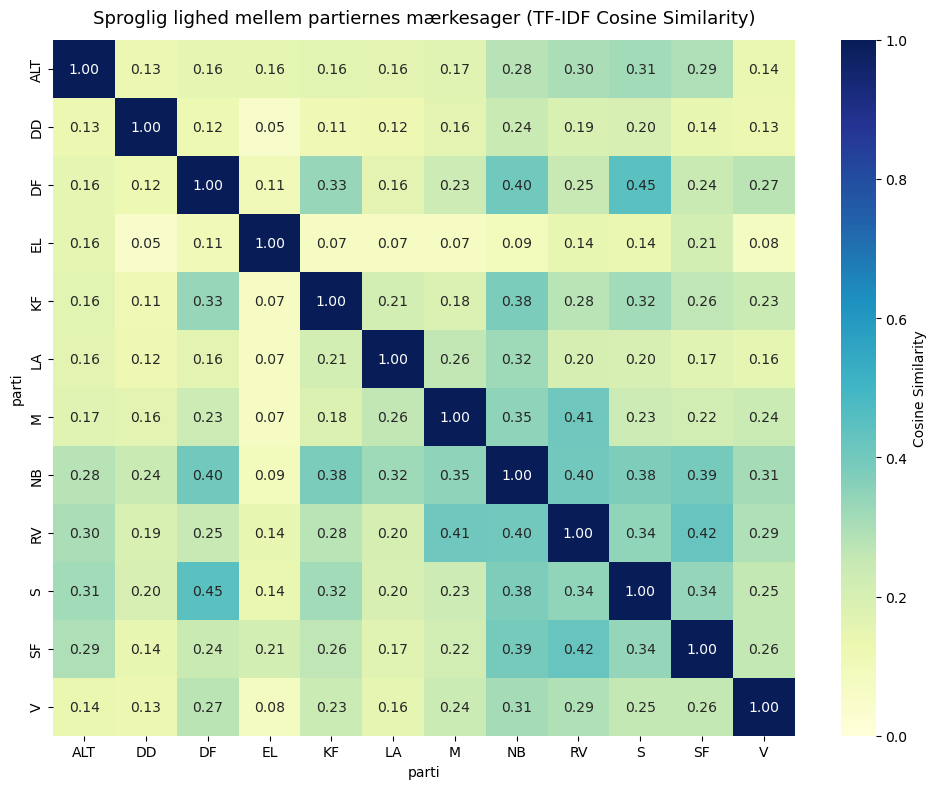

,Ord,S TF-IDF,M TF-IDF,Fælles bidrag
0,sætte,0.098,0.125,0.0123
1,socialdemokrati,0.262,0.044,0.0115
2,sygehus,0.143,0.058,0.0083
3,verden,0.052,0.125,0.0065
4,uddannelse,0.057,0.104,0.0059
5,hel,0.083,0.062,0.0052
6,indføre,0.056,0.090,0.0050
7,investere,0.046,0.106,0.0049
8,handle,0.079,0.053,0.0042
9,løse,0.031,0.127,0.0040


In [7]:
# --- CELLE 7: COSINE SIMILARITY – hvilke partier skriver ens på hjemmesiden? ---
sim_df = pd.DataFrame(cosine_similarity(tfidf_matrix), index=party_docs.index, columns=party_docs.index)

plt.figure(figsize=(10, 8))
sns.heatmap(sim_df, annot=True, fmt=".2f", cmap="YlGnBu", vmin=0, vmax=1,
            cbar_kws={"label": "Cosine Similarity"})
plt.title("Sproglig lighed mellem partiernes mærkesager (TF-IDF Cosine Similarity)", fontsize=13, pad=12)
plt.tight_layout(); plt.show()

def get_shared_topics(party1, party2, top_n=10):
    i1, i2 = list(party_docs.index).index(party1), list(party_docs.index).index(party2)
    v1, v2 = tfidf_matrix[i1].toarray().flatten(), tfidf_matrix[i2].toarray().flatten()
    top = (v1 * v2).argsort()[::-1][:top_n]
    return pd.DataFrame({"Ord": feature_names[top], f"{party1} TF-IDF": v1[top].round(3),
                         f"{party2} TF-IDF": v2[top].round(3), "Fælles bidrag": (v1 * v2)[top].round(4)})

display(get_shared_topics("S", "M"))      # skift partierne for at sammenligne andre

emne,Sundhed og ældrepleje,Klima og miljø,Skoler og børnepasning,Økonomi og skat,Flygtninge og indvandrere,Retspolitik og tryghed,Forsvar og sikkerhed,Pension og tilbagetrækning
parti,,,,,,,,
ALT,5.0,49.5,15.8,22.8,5.0,2.0,0.0,0.0
DD,6.7,10.0,26.7,41.7,5.0,8.3,0.0,1.7
DF,20.6,3.4,6.4,15.0,24.3,28.5,1.1,0.7
EL,11.6,46.5,4.7,25.6,11.6,0.0,0.0,0.0
KF,15.9,20.3,14.5,22.5,10.1,16.7,0.0,0.0
LA,4.9,23.3,0.0,48.5,1.0,20.4,0.0,1.9
M,16.3,10.2,22.4,38.8,5.1,1.0,2.0,4.1
NB,11.2,12.1,17.3,30.5,14.6,7.8,4.4,2.1
RV,11.3,29.7,34.2,14.8,3.5,1.9,2.6,1.9


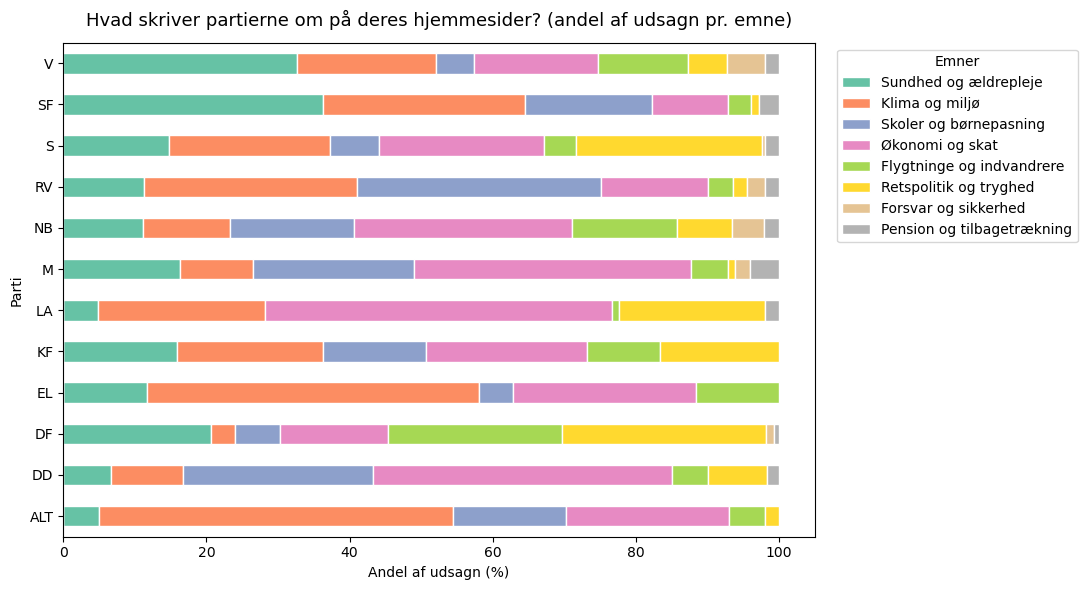

In [8]:
# --- CELLE 8: EMNER – hvor meget fylder hvert af de 8 emner hos hvert parti? ---
# (I stedet for LDA-emner bruger vi de 8 mærkesags-kategorier som emner.)
emne_navne = list(KATEGORIER)
party_topic_share = (pd.crosstab(udsagn["parti"], udsagn["emne"], normalize="index")
                       .reindex(columns=emne_navne, fill_value=0) * 100)
display(party_topic_share.round(1))

ax = party_topic_share.plot(kind="barh", stacked=True, figsize=(11, 6), colormap="Set2", edgecolor="white")
plt.title("Hvad skriver partierne om på deres hjemmesider? (andel af udsagn pr. emne)", fontsize=13, pad=12)
plt.xlabel("Andel af udsagn (%)"); plt.ylabel("Parti")
plt.legend(title="Emner", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout(); plt.show()

In [9]:
# --- CELLE 9: SEMANTICS – STANCE DETECTION (FOR / IMOD) PÅ MÆRKESAGERNE ---
# Samme model som på citaterne. Vi bruger For/Imod i stedet for positiv/negativ:
# en mærkesag er altid "for" partiets eget forslag, og tonen siger ikke noget om holdningen
# ("Stop indvandringen" lyder negativt, men er FOR en stram udlændingepolitik).
from transformers import pipeline

stance_classifier = pipeline("zero-shot-classification", model="MoritzLaurer/mDeBERTa-v3-base-mnli-xnli")

# Hvert emne får én påstand, som alle partier måles op mod. Retningen er valgt, så den kan
# sammenlignes med afstemningerne (For = stemmer for lovforslag i den retning).
stance_config = {
    "Økonomi og skat":            "lavere skatter og afgifter",
    "Sundhed og ældrepleje":      "flere penge og mere personale til sundhed og ældrepleje",
    "Klima og miljø":             "en mere ambitiøs klimapolitik og grøn omstilling",
    "Skoler og børnepasning":     "flere ressourcer til skoler, uddannelse og børnepasning",
    "Flygtninge og indvandrere":  "en stram udlændingepolitik",
    "Retspolitik og tryghed":     "hårdere straffe og mere politi",
    "Forsvar og sikkerhed":       "et stærkere forsvar",
    "Pension og tilbagetrækning": "bedre muligheder for tidlig tilbagetrækning",
}

def maal_stance(df_emne, stance_beskrivelse):
    labels = [f"for {stance_beskrivelse}", f"imod {stance_beskrivelse}", "neutral"]
    results = stance_classifier(df_emne["udsagn"].tolist(), candidate_labels=labels,
                                hypothesis_template="Denne tekst fra et partis valgprogram er {}.")
    df_emne = df_emne.copy()
    df_emne["for_prob"] = [dict(zip(r["labels"], r["scores"]))[labels[0]] for r in results]
    df_emne["imod_prob"] = [dict(zip(r["labels"], r["scores"]))[labels[1]] for r in results]
    df_emne["stance_score"] = df_emne["for_prob"] - df_emne["imod_prob"]
    return df_emne

# Modellen er langsom på en laptop. Nye Borgerlige har ~250 udsagn alene om økonomi,
# så vi tager højst MAX_PR_PARTI udsagn pr. parti pr. emne (tilfældigt udvalgt, men det samme hver gang).
MAX_PR_PARTI = 40

resultater = []
for emne, beskrivelse in stance_config.items():
    sub = (udsagn[udsagn["emne"] == emne]
           .sample(frac=1, random_state=42)                # bland rækkefølgen ...
           .groupby("parti").head(MAX_PR_PARTI))            # ... og tag de første MAX_PR_PARTI pr. parti
    print(f"=== {emne.upper()}: «{beskrivelse}» · {len(sub)} udsagn ===")
    if sub.empty:
        continue
    sub = maal_stance(sub, beskrivelse)
    sub["stance_beskrivelse"] = beskrivelse
    resultater.append(sub)

    oversigt = (sub.groupby("parti").agg(antal_udsagn=("stance_score", "count"),
                                         gennemsnit_stance=("stance_score", "mean"))
                   .sort_values("gennemsnit_stance", ascending=False))
    display(oversigt.round(2))
    print("-> MEST FOR:")
    for _, r in sub.nlargest(2, "stance_score").iterrows():
        print(f"   [+{r['stance_score']:.2f}] {r['parti']} · {r['maerkesag']}: \"{r['udsagn'][:150]}\"")
    print("-> MEST IMOD:")
    for _, r in sub.nsmallest(2, "stance_score").iterrows():
        print(f"   [{r['stance_score']:.2f}] {r['parti']} · {r['maerkesag']}: \"{r['udsagn'][:150]}\"")
    print("\n" + "-" * 80 + "\n")

all_stance = pd.concat(resultater, ignore_index=True)

W1124 10:50:41.691000 21409 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


config.json:   0%|          | 0.00/1.07k [00:00<?, ?B/s]

/Users/salmahirsi/miniforge3/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


model.safetensors: reconstructing file:   0%|          |  0.00B /  558MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

... (20 outputs left out)

,antal_udsagn,gennemsnit_stance
parti,,
DF,3,0.56
V,8,0.56
M,2,0.36
NB,31,0.32
RV,8,0.01
S,2,-0.03


-> MEST FOR:
   [+1.00] NB · Vi skal i gang - investeringer her og nu: "Nye Borgerlige fremlagde allerede i 2016 en fuldt finansieret plan, som styrker dansk forsvar og opfylder NATO-aftalen om 2 % af BNP."
   [+0.98] V · Vi skal tage større ansvar for Danmarks sikkerhed: "Derfor har vi i Venstre været med til at sikre, at Danmark senest i 2030 kommer til at bruge to procent af vores BNP på forsvaret , så vi lever op til"
-> MEST IMOD:
   [-0.58] NB · Tydelig mærkning af halalcertificerede varer og produkter: "Nye Borgerlige mener, at forbrugerne ikke er tilstrækkeligt oplyst om, hvorvidt kødproduktionen er sket under forsvarlige vilkår for dyrene."
   [-0.37] NB · Ingen rewilding-projekter, der mishandler dyrene: "For statsligt dyrplageri, hvor dyr skal sulte ihjel, fordi nogle politikere har en romantisk forestilling om natur og dyrehold, kan på ingen måde fors"

--------------------------------------------------------------------------------

=== PENSION OG TILBAGETRÆKNING: «bedre m

,antal_udsagn,gennemsnit_stance
parti,,
DF,2,0.77
LA,2,0.59
V,3,0.47
NB,15,0.25
S,11,0.23
M,4,0.22
SF,7,0.17
RV,6,0.15
DD,1,0.09


-> MEST FOR:
   [+0.85] DF · Ældre og seniorer: "Her mener Dansk Folkeparti, at danskerne skal sikres en pensionsalder, hvor der stadig er mange gode leveår tilbage, når man trækker sig fra arbejdsma"
   [+0.71] NB · Pension til Arne - men også en skatterabat til Bjarne: "Derfor vil vi give danskerne større råderet over deres egne penge, så de selv kan træffe valget om, hvornår de vil gå på pension."
-> MEST IMOD:
   [-0.14] NB · Flere private velfærdsiværksættere: "Store fødselsårgange går på pension, hvilket betyder højere udgifter til sociale pensioner, sundhedsydelser, hjemmepleje og plejehjem."
   [-0.13] SF · Værdigheden tilbage i ældreplejen: "Og problemet er blevet større siden efterlønnen blev udfaset."

--------------------------------------------------------------------------------



Gemte 1727 udsagn i data/maerkesager_stance_results.csv
stance_label
For        1077
Neutral     338
Imod        312


emne,Økonomi og skat,Sundhed og ældrepleje,Klima og miljø,Skoler og børnepasning,Flygtninge og indvandrere,Retspolitik og tryghed,Forsvar og sikkerhed,Pension og tilbagetrækning
parti,,,,,,,,
ALT,0.10,0.06,0.39,0.38,-0.12,-0.02,NaN,NaN
DD,0.21,0.03,0.27,0.29,0.10,-0.08,NaN,NaN
DF,0.30,0.07,0.09,0.18,0.00,0.11,0.56,0.77
EL,0.38,-0.08,0.34,-0.27,-0.35,NaN,NaN,NaN
KF,0.36,-0.01,0.53,0.44,0.14,0.12,NaN,NaN
LA,0.06,-0.09,0.26,NaN,NaN,-0.03,NaN,0.59
M,0.15,0.03,0.50,0.39,-0.02,NaN,0.36,0.22
NB,0.21,0.09,0.18,0.21,0.07,0.07,0.32,0.25
RV,0.14,-0.01,0.42,0.36,0.01,0.05,0.01,0.15


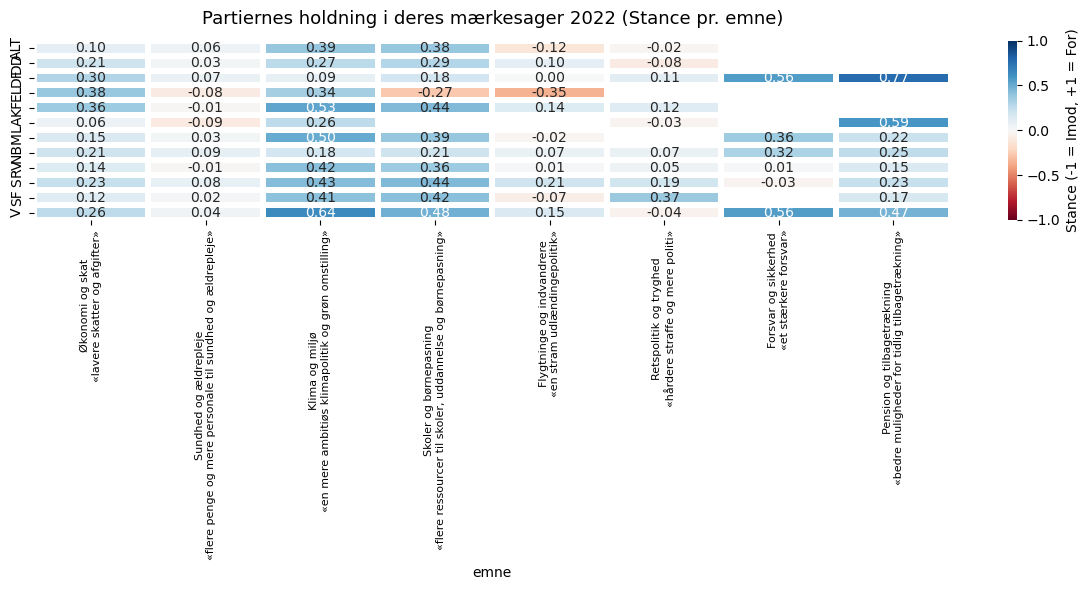

In [13]:
# --- CELLE 10: SAML, GEM OG HEATMAP ---
all_stance["stance_label"] = np.select(
    [all_stance["stance_score"] > 0.05, all_stance["stance_score"] < -0.05], ["For", "Imod"], "Neutral")

columns_to_save = ["parti", "party", "maerkesag", "udsagn", "emne", "stance_beskrivelse",
                   "for_prob", "imod_prob", "stance_score", "stance_label"]
all_stance[columns_to_save].to_csv(data_dir / "maerkesager_stance_results.csv", index=False, encoding="utf-8-sig")
print(f"Gemte {len(all_stance)} udsagn i data/maerkesager_stance_results.csv")
print(all_stance["stance_label"].value_counts().to_string())

# Partiernes gennemsnitlige stance pr. emne (kun hvor partiet har mindst 2 udsagn)
grp = all_stance.groupby(["parti", "emne"])["stance_score"].agg(["mean", "count"]).reset_index()
stance_matrix = (grp[grp["count"] >= 2].pivot(index="parti", columns="emne", values="mean")
                   .reindex(columns=[e for e in stance_config if e in set(grp["emne"])]).round(2))
display(stance_matrix)

plt.figure(figsize=(12, 6))
sns.heatmap(stance_matrix, annot=True, fmt=".2f", cmap="RdBu", center=0, vmin=-1, vmax=1,
            linewidths=3, linecolor="white",
            xticklabels=[f"{e}\n«{stance_config[e]}»" for e in stance_matrix.columns],
            cbar_kws={"label": "Stance (-1 = Imod, +1 = For)"})
plt.title("Partiernes holdning i deres mærkesager 2022 (Stance pr. emne)", fontsize=13, pad=12)
plt.xticks(fontsize=8); plt.ylabel("")
plt.tight_layout(); plt.show()

In [11]:
from pathlib import Path
print(Path("/Users/salmahirsi/Documents/GitHub/Politics-Network/data/maerkesager_stance_results.csv").exists())

False


In [12]:
from pathlib import Path
print(list(Path("/Users/salmahirsi/Documents/GitHub/Politics-Network").rglob("maerkesager_stance_results.csv")))

[]


In [10]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.patches import Patch

MAPPE = "/Users/salmahirsi/Documents/GitHub/Politics-Network/data/"
stance = pd.read_csv(MAPPE + "maerkesager_stance_results.csv", encoding="utf-8-sig")
stemmer = pd.read_csv(MAPPE + "processed/stemmer_2022_2026.csv")

KOBLING = {   # mærkesags-emne (det de skrev)  ->  emne på lovene (det de stemte om)
    "Økonomi og skat":            ["Økonomi, skat & energipriser"],
    "Sundhed og ældrepleje":      ["Sundhed & psykiatri", "Ældre & velfærd"],
    "Klima og miljø":             ["Klima, miljø & landbrug"],
    "Skoler og børnepasning":     ["Uddannelse & forskning", "Kultur, medier & kirke"],
    "Flygtninge og indvandrere":  ["Udlændinge & integration"],
    "Retspolitik og tryghed":     ["Retsvæsen & politi"],
    "Forsvar og sikkerhed":       ["Forsvar & sikkerhed"],
    "Pension og tilbagetrækning": "TITEL:pension|efterløn|tilbagetrækning",   # intet eget lov-emne: søg i lovens titel
}
MIN_UDSAGN = 3      # færre udsagn end det -> "For lidt data"

# ---------- SKREV: For / Imod / Neutral pr. parti pr. emne (fra mærkesagerne) ----------
stance["v"] = stance["stance_label"].map({"For": 1, "Neutral": 0, "Imod": -1})
skrev = stance.groupby(["parti", "emne"])["v"].agg(score="mean", n="size").reset_index()
skrev["skrev"] = np.select([skrev["score"] > 0.15, skrev["score"] < -0.15], ["For", "Imod"], "Neutral")

# ---------- STEMTE: For / Imod / Blandet pr. parti pr. emne ----------
v = stemmer[(stemmer["afstemningstype"] == "Endelig vedtagelse") & stemmer["stemme"].isin(["For", "Imod"])].copy()
v["for"] = (v["stemme"] == "For").astype(int)

rækker = []
for emne, lov_emner in KOBLING.items():
    if isinstance(lov_emner, str) and lov_emner.startswith("TITEL:"):
        sub = v[v["titel_kort"].str.contains(lov_emner[6:], case=False, na=False)]
    else:
        sub = v[v["emne"].isin(lov_emner)]
    for parti, g in sub.groupby("parti"):
        rækker.append({"parti": parti, "emne": emne, "andel_for": g["for"].mean(),
                       "antal_love": g["afstemning_id"].nunique()})
stemte = pd.DataFrame(rækker)
stemte["stemte"] = np.select([stemte["andel_for"] >= 0.6, stemte["andel_for"] <= 0.4], ["For", "Imod"], "Blandet")

# ---------- DOM: holder de, hvad de skrev? ----------
r = skrev.merge(stemte, on=["parti", "emne"], how="inner")
r["dom"] = np.select(
    [r["n"] < MIN_UDSAGN,
     r["skrev"] == r["stemte"],
     ((r["skrev"] == "For") & (r["stemte"] == "Imod")) | ((r["skrev"] == "Imod") & (r["stemte"] == "For"))],
    ["For lidt data", "Holder", "Holder ikke"], "Uklart")
display(r["dom"].value_counts())
print("Partier med mærkesager, men uden afstemninger (fx NB, der ikke findes som parti efter valget):",
      sorted(set(skrev["parti"]) - set(stemte["parti"])))

# ---------- FIGUR 1: Ét felt pr. parti pr. emne ----------
FARVE = {"Holder": "#4caf50", "Holder ikke": "#e53935", "Uklart": "#ffd54f", "For lidt data": "#e0e0e0"}
partier = r.groupby("parti")["n"].sum().sort_values(ascending=False).index
emner = [e for e in KOBLING if e in set(r["emne"])]
fig, ax = plt.subplots(figsize=(2.6 * len(emner), 0.95 * len(partier) + 1.8))
for i, p in enumerate(partier):
    for j, e in enumerate(emner):
        rk = r[(r["parti"] == p) & (r["emne"] == e)]
        if rk.empty:
            ax.add_patch(plt.Rectangle((j, i), 1, 1, color="white", ec="#ddd")); continue
        rk = rk.iloc[0]
        ax.add_patch(plt.Rectangle((j, i), 1, 1, color=FARVE[rk["dom"]], ec="white", lw=3))
        ax.text(j + 0.5, i + 0.5, f"Skrev: {rk['skrev']}\nStemte: {rk['stemte']}\n({rk['n']} udsagn)",
                ha="center", va="center", fontsize=9)
ax.set_xlim(0, len(emner)); ax.set_ylim(len(partier), 0)
ax.set_xticks(np.arange(len(emner)) + 0.5)
ax.set_xticklabels([f"{e}\n«{stance.loc[stance['emne'] == e, 'stance_beskrivelse'].iloc[0]}»" for e in emner], fontsize=9)
ax.xaxis.tick_top()
ax.set_yticks(np.arange(len(partier)) + 0.5); ax.set_yticklabels(partier, fontsize=12, fontweight="bold")
ax.tick_params(length=0)
for s in ax.spines.values(): s.set_visible(False)
ax.legend(handles=[Patch(color=c, label=l) for l, c in FARVE.items()], loc="upper center",
          bbox_to_anchor=(0.5, -0.02), ncol=4, frameon=False, fontsize=11)
ax.set_title("Holder partierne, hvad de skrev i deres mærkesager i 2022?\n", fontsize=15)
plt.tight_layout(); plt.show()

# ---------- FIGUR 2: Hvor ofte holder hvert parti? ----------
tæl = (r[r["dom"] != "For lidt data"].groupby(["parti", "dom"]).size().unstack(fill_value=0)
        .reindex(columns=["Holder", "Uklart", "Holder ikke"], fill_value=0))
tæl = tæl.loc[tæl.sum(axis=1).sort_values().index]
tæl.plot.barh(stacked=True, color=[FARVE[c] for c in tæl.columns], figsize=(9, 6), width=0.75)
plt.xlabel("Antal emner"); plt.ylabel("")
plt.title("Antal emner hvor partiet holder / ikke holder, hvad det skrev i sine mærkesager")
plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left", frameon=False); plt.tight_layout(); plt.show()

# ---------- Gem resultatet ----------
r.round(3).to_csv(MAPPE + "maerkesager_vs_stemmer.csv", index=False, encoding="utf-8-sig")
print("Gemt: maerkesager_vs_stemmer.csv")

# ---------- Tjek de røde felter: hvad skrev de egentlig? ----------
def vis(parti, emne):
    display(stance[(stance["parti"] == parti) & (stance["emne"] == emne)][["maerkesag", "udsagn", "stance_label"]])
display(r[r["dom"] == "Holder ikke"][["parti", "emne", "skrev", "stemte", "n", "andel_for", "antal_love"]].round(2))
vis("V", "Klima og miljø")

FileNotFoundError: [Errno 2] No such file or directory: '/Users/salmahirsi/Documents/GitHub/Politics-Network/data/maerkesager_stance_results.csv'